# ResNet 与 CIFAR-10

每个残差块把主分支与捷径相加。三个阶段的通道数依次为 4、8、16，阶段切换时下采样。

保留原训练量：500 张训练图、3 轮、每批 16 张；独立测试 100 张。
纯 Python CPU 训练需要时间。请在 `examples` 目录运行。

In [6]:
from qutai import Stream, nn, visualization
from datasets import load_cifar10, CIFAR10_NAMES

## 1. 读取数据，看看一张图片

图像张量使用 `(批次, 通道, 高, 宽)`，分批器将像素除以 255。训练集和测试集来自官方不同划分。

▱▱▱▱▱▱▱▱▱▱▱▱▱▱▱▱▱▱▱▱▱▱▱▱   0.0%  0/32  0.0s
输入形状： (16, 3, 32, 32) 第一张的标签： automobile


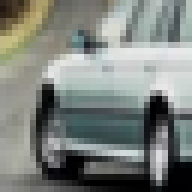

In [7]:
width = 4
train_count = 500
test_count = 100
epochs = 3
batch_size = 16
learning_rate = 0.05
names = CIFAR10_NAMES

train_images, train_targets = load_cifar10("train")
test_images, test_targets = load_cifar10("test")
inputs, targets = next(iter(Stream(train_images, train_targets, batch_size=batch_size, limit=train_count)))
print("输入形状：", inputs.shape, "第一张的标签：", names[targets[0]])
visualization.Image.from_tensor(inputs[0], value_range=(0, 1))

## 2. 搭建模型

每个残差块把主分支与捷径相加。三个阶段的通道数依次为 4、8、16，阶段切换时下采样。
交叉熵接收原始得分和整数标签，训练时无需先算 Softmax。

In [8]:
c1, c2, c3 = width, width * 2, width * 4
model = nn.Model([
    # 输入：3 个通道，32×32。
    nn.Conv2d(3, c1, 3, padding=1, bias=False, seed=42),
    nn.BatchNorm2d(c1),
    nn.ReLU(),

    # 阶段一：c1 个通道，32×32。
    nn.ResNetBlock(c1, c1, seed=100),
    nn.ResNetBlock(c1, c1, seed=103),
    nn.ResNetBlock(c1, c1, seed=106),

    # 阶段二：第一块下采样，得到 c2 个通道、16×16。
    nn.ResNetBlock(c1, c2, stride=2, seed=120),
    nn.ResNetBlock(c2, c2, seed=123),
    nn.ResNetBlock(c2, c2, seed=126),

    # 阶段三：第一块下采样，得到 c3 个通道、8×8。
    nn.ResNetBlock(c2, c3, stride=2, seed=140),
    nn.ResNetBlock(c3, c3, seed=143),
    nn.ResNetBlock(c3, c3, seed=146),

    # 每个通道取平均值，再输出十个类别的得分。
    nn.GlobalAvgPool2d(),
    nn.Linear(c3, 10, seed=200),
])
optimizer = nn.SGD(model, learning_rate=learning_rate, momentum=0.9, weight_decay=1e-4)
loss_function = nn.CrossEntropy()
# visualization.Network(model)

### 观察每层如何改变形状

只取一张图，在预测状态下逐层查看；模型中的参数和 BatchNorm 统计保持原样。

In [9]:
output = inputs[:1]
for layer in model.layers:
    output = nn.Model([layer])(output, train=False)
    print(type(layer).__name__, output.shape)

Conv2d (1, 4, 32, 32)
BatchNorm2d (1, 4, 32, 32)
ReLU (1, 4, 32, 32)
ResNetBlock (1, 4, 32, 32)
ResNetBlock (1, 4, 32, 32)
ResNetBlock (1, 4, 32, 32)
ResNetBlock (1, 8, 16, 16)
ResNetBlock (1, 8, 16, 16)
ResNetBlock (1, 8, 16, 16)
ResNetBlock (1, 16, 8, 8)
ResNetBlock (1, 16, 8, 8)
ResNetBlock (1, 16, 8, 8)
GlobalAvgPool2d (1, 16)
Linear (1, 10)


## 3. 按批训练

每轮重新打乱训练子集，然后逐批更新参数。训练循环保持与回归、Iris 相同的四个步骤；每轮打印最后一批的损失。

In [10]:
data = Stream(train_images, train_targets, batch_size=batch_size, limit=train_count)

for epoch in range(epochs):
    for inputs, targets in data:
        optimizer.zero_grad()
        loss = loss_function(model(inputs), targets)
        loss.backward()
        optimizer.step()
    print(f"epoch {epoch+1}/{epochs}  最后一批 loss {loss.item():.6f}")

▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰ 100.0%  32/32  184.2s
epoch 1/3  最后一批 loss 2.066623
▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰ 100.0%  32/32  186.3s
epoch 2/3  最后一批 loss 2.129237
▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰ 100.0%  32/32  184.6s
epoch 3/3  最后一批 loss 1.898902


## 4. 独立测试

`train=False` 暂停计算图记录；ResNet 的 BatchNorm 也会使用训练得到的统计量。直接取最大得分的编号作为类别。

In [11]:
correct, total = 0, 0
for inputs, targets in Stream(test_images, test_targets, batch_size=batch_size, limit=test_count, progress=False):
    predictions = model(inputs, train=False).argmax(axis=-1)
    correct += sum(prediction == target for prediction, target in zip(predictions, targets))
    total += len(targets)
print(f"测试准确率：{correct}/{total} = {correct / total:.1%}")

测试准确率：16/100 = 16.0%


In [12]:
inputs, targets = next(iter(Stream(test_images, test_targets, batch_size=4, progress=False)))
predictions = model(inputs, train=False).argmax(axis=-1)
visualization.Table([[names[target], names[prediction]] for target, prediction in zip(targets, predictions)], columns=["正确类别", "预测类别"])

正确类别,预测类别
dog,truck
truck,deer
airplane,automobile
truck,automobile
